# Stroke Prediction using Boosting (AdaBoost & XGBoost)
**Machine Learning Mini-Project - Group 10**

| | |
|---|---|
| **Topic** | Boosting - AdaBoost / XGBoost |
| **Dataset** | Kaggle *Stroke Prediction Dataset* (`healthcare-dataset-stroke-data.csv`, 5,110 patients) |
| **Question** | Can a patient's risk of stroke be predicted using health and demographic factors? |
| **Team members** | *(add names / roll numbers here)* |

**Workflow:** Data loading -> Preprocessing -> EDA -> Statistical analysis -> Feature engineering -> Model training -> Prediction -> Evaluation -> Visualisation -> Interpretation

> **How to run in Google Colab:** *Runtime -> Run all*. When the first data cell asks for it, upload `healthcare-dataset-stroke-data.csv`. No extra installation is needed (pandas, scikit-learn, XGBoost, seaborn and SciPy are pre-installed in Colab).

In [1]:
import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold, RandomizedSearchCV,
                                     cross_val_predict, cross_val_score, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, precision_recall_curve, log_loss)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print('Libraries loaded.')

Libraries loaded.


---
## A. Data Loading
The dataset is loaded with pandas and its basic structure is displayed: size, column names, data types, first and last records, and summary statistics.

In [2]:
DATA = 'healthcare-dataset-stroke-data.csv'
if not os.path.exists(DATA):
    # Google Colab: upload the CSV when prompted
    try:
        from google.colab import files
        print('Please upload healthcare-dataset-stroke-data.csv')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Place {DATA} in the same folder as this notebook.')

df_raw = pd.read_csv(DATA)

print('Number of rows   :', df_raw.shape[0])
print('Number of columns:', df_raw.shape[1])
print('\nColumn names:', list(df_raw.columns))
print('\nData types:\n', df_raw.dtypes)

Number of rows   : 5110
Number of columns: 12

Column names: ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Data types:
 id                     int64
gender                   str
age                  float64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object


In [3]:
print('First 5 records')
display(df_raw.head())
print('Last 5 records')
display(df_raw.tail())
print('Basic information')
df_raw.info()
print('\nSummary statistics (numerical)')
display(df_raw.describe().T)

First 5 records


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Last 5 records


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


Basic information
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB

Summary statistics (numerical)


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


---
## B. Data Preprocessing
Before any modelling, the data is audited for missing values, duplicates, wrong or inconsistent entries and variable types.

In [4]:
# --- Missing values ---
print('Missing values per column:')
print(df_raw.isna().sum()[lambda s: s > 0])
print(f'\nBMI missing: {df_raw.bmi.isna().sum()} rows ({df_raw.bmi.isna().mean():.1%})')

# Is the missingness informative?
miss = df_raw.bmi.isna()
print(f'Stroke rate when BMI is missing : {df_raw.loc[miss, "stroke"].mean():.1%}')
print(f'Stroke rate when BMI is present : {df_raw.loc[~miss, "stroke"].mean():.1%}')

# --- Duplicates ---
print('\nDuplicate rows            :', df_raw.duplicated().sum())
print('Duplicate patient ids     :', df_raw['id'].duplicated().sum())

# --- Inappropriate / inconsistent values ---
print('\nCategorical value counts:')
for c in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(f'  {c}: {df_raw[c].value_counts().to_dict()}')

print('\nValue range checks:')
print('  age  min/max               :', df_raw.age.min(), '/', df_raw.age.max())
print('  age < 2 (infants)          :', (df_raw.age < 2).sum())
print('  bmi  min/max               :', df_raw.bmi.min(), '/', df_raw.bmi.max())
print('  bmi > 60 (extreme)         :', (df_raw.bmi > 60).sum())
print('  glucose min/max            :', df_raw.avg_glucose_level.min(), '/', df_raw.avg_glucose_level.max())
print("  work_type='children' & age>=18:", ((df_raw.work_type == 'children') & (df_raw.age >= 18)).sum())
print("  never_worked & age<16          :", ((df_raw.work_type == 'Never_worked') & (df_raw.age < 16)).sum())
print("  ever_married='Yes' & age<16    :", ((df_raw.ever_married == 'Yes') & (df_raw.age < 16)).sum())

Missing values per column:
bmi    201
dtype: int64

BMI missing: 201 rows (3.9%)
Stroke rate when BMI is missing : 19.9%
Stroke rate when BMI is present : 4.3%

Duplicate rows            : 0
Duplicate patient ids     : 0

Categorical value counts:
  gender: {'Female': 2994, 'Male': 2115, 'Other': 1}
  ever_married: {'Yes': 3353, 'No': 1757}
  work_type: {'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}
  Residence_type: {'Urban': 2596, 'Rural': 2514}
  smoking_status: {'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}

Value range checks:
  age  min/max               : 0.08 / 82.0
  age < 2 (infants)          : 120
  bmi  min/max               : 10.3 / 97.6
  bmi > 60 (extreme)         : 13
  glucose min/max            : 55.12 / 271.74
  work_type='children' & age>=18: 0
  never_worked & age<16          : 8
  ever_married='Yes' & age<16    : 0


### Findings of the data audit
| Check | Result | Decision |
|---|---|---|
| Missing values | Only `bmi` has gaps: **201 rows (3.9%)** | Impute with the **median** (inside the pipeline) and add a `bmi_missing` flag |
| Is the gap informative? | Stroke rate is **19.9%** when BMI is missing vs **4.3%** when present | Keep the flag as a feature - the missingness itself carries signal |
| Duplicates | 0 duplicate rows, 0 duplicate ids | Nothing to remove |
| Inconsistent values | `gender = 'Other'` occurs **once** | Drop this single row (cannot be learned or stratified) |
| Implausible values | 13 patients with BMI > 60; 120 infants (age < 2) | Keep - they are rare but valid; tree models are robust to extremes (see outlier analysis) |
| Logical consistency | No `children` aged 18+; nobody under 16 is married; 8 `Never_worked` under 16 (children) | Consistent, no action |
| Identifier | `id` | Drop - it has no predictive meaning |
| Class balance | 249 strokes vs 4,861 non-strokes (**about 19.5 : 1**) | Handle with class weighting and a tuned decision threshold (Section E/F) |

In [5]:
df = df_raw.copy()

# 1. 'id' is only an identifier -> no predictive meaning, would let the model memorise rows
df = df.drop(columns=['id'])

# 2. gender == 'Other' appears exactly once -> too rare to learn from, and it breaks stratification
print("Rows with gender == 'Other':", (df.gender == 'Other').sum())
df = df[df.gender != 'Other'].reset_index(drop=True)

# 3. Binary categorical -> 0/1
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})
df['ever_married'] = df['ever_married'].map({'No': 0, 'Yes': 1})
df['Residence_type'] = df['Residence_type'].map({'Rural': 0, 'Urban': 1})

# 4. Explicit missing-value indicator for BMI (see the missingness check above)
df['bmi_missing'] = df['bmi'].isna().astype(int)

# 'smoking_status == Unknown' is a legitimate category (not NaN) and is kept as its own level.
print('Cleaned shape:', df.shape)
display(df.head())

NUM_COLS = ['age', 'avg_glucose_level', 'bmi']
BIN_COLS = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'bmi_missing']
CAT_COLS = ['work_type', 'smoking_status']
TARGET = 'stroke'

Rows with gender == 'Other': 1
Cleaned shape: (5109, 12)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,bmi_missing
0,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1,0
1,0,61.0,0,0,1,Self-employed,0,202.21,NaN,never smoked,1,1
2,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1,0
3,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1,0
4,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1,0


In [6]:
# Leakage-safe preprocessing: the transformer is *fitted on training data only* (inside the pipeline)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), NUM_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
        ('bin', 'passthrough', BIN_COLS),
    ],
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform='pandas')
print('Preprocessor defined.')

Preprocessor defined.


### Why each preprocessing technique was chosen
| Technique | Applied to | Reason |
|---|---|---|
| **Median imputation** | `bmi` | BMI is right-skewed (skewness 1.06) with extreme values, so the median is a more robust fill value than the mean |
| **Missing indicator** (`bmi_missing`) | `bmi` | Missing BMI is associated with a much higher stroke rate, so the information is kept rather than hidden |
| **Binary (0/1) encoding** | `gender`, `ever_married`, `Residence_type` | Two-level variables need only one numeric column |
| **One-hot encoding** | `work_type`, `smoking_status` | These are nominal with no natural order, so label-encoding would invent a false ordering |
| **Standard scaling** | `age`, `avg_glucose_level`, `bmi` | Puts numeric features on the same scale. *Note:* tree-based boosting is scale-invariant, so this does **not** change the results; it is applied because the assignment asks for it and it keeps the pipeline reusable for distance/linear models |
| **Fit on training data only** | All of the above | The imputer/scaler/encoder live inside a scikit-learn `Pipeline`, so test-set statistics never leak into training and cross-validation is honest |
| **Outliers kept** | glucose, BMI | High glucose values are clinically meaningful (diabetes) - removing them would remove the signal. Boosted trees split on thresholds, so extreme values do little harm |

---
## C. Exploratory Data Analysis (EDA)
Each plot is followed by what it tells us. For plotting only, missing BMI values are filled with the median.

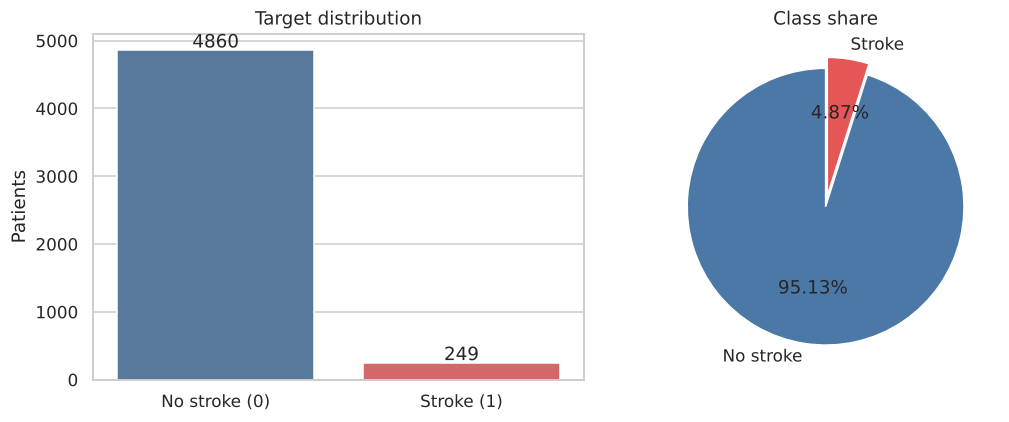

Imbalance ratio (no stroke : stroke) = 19.5 : 1


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
counts = df[TARGET].value_counts().sort_index()
sns.barplot(x=['No stroke (0)', 'Stroke (1)'], y=counts.values, ax=ax[0], palette=['#4C78A8', '#E45756'])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 40, str(v), ha='center')
ax[0].set_title('Target distribution'); ax[0].set_ylabel('Patients')
ax[1].pie(counts.values, labels=['No stroke', 'Stroke'], autopct='%1.2f%%', colors=['#4C78A8', '#E45756'],
          startangle=90, explode=[0, 0.08])
ax[1].set_title('Class share')
savefig('01_target_distribution')
print(f'Imbalance ratio (no stroke : stroke) = {counts[0] / counts[1]:.1f} : 1')

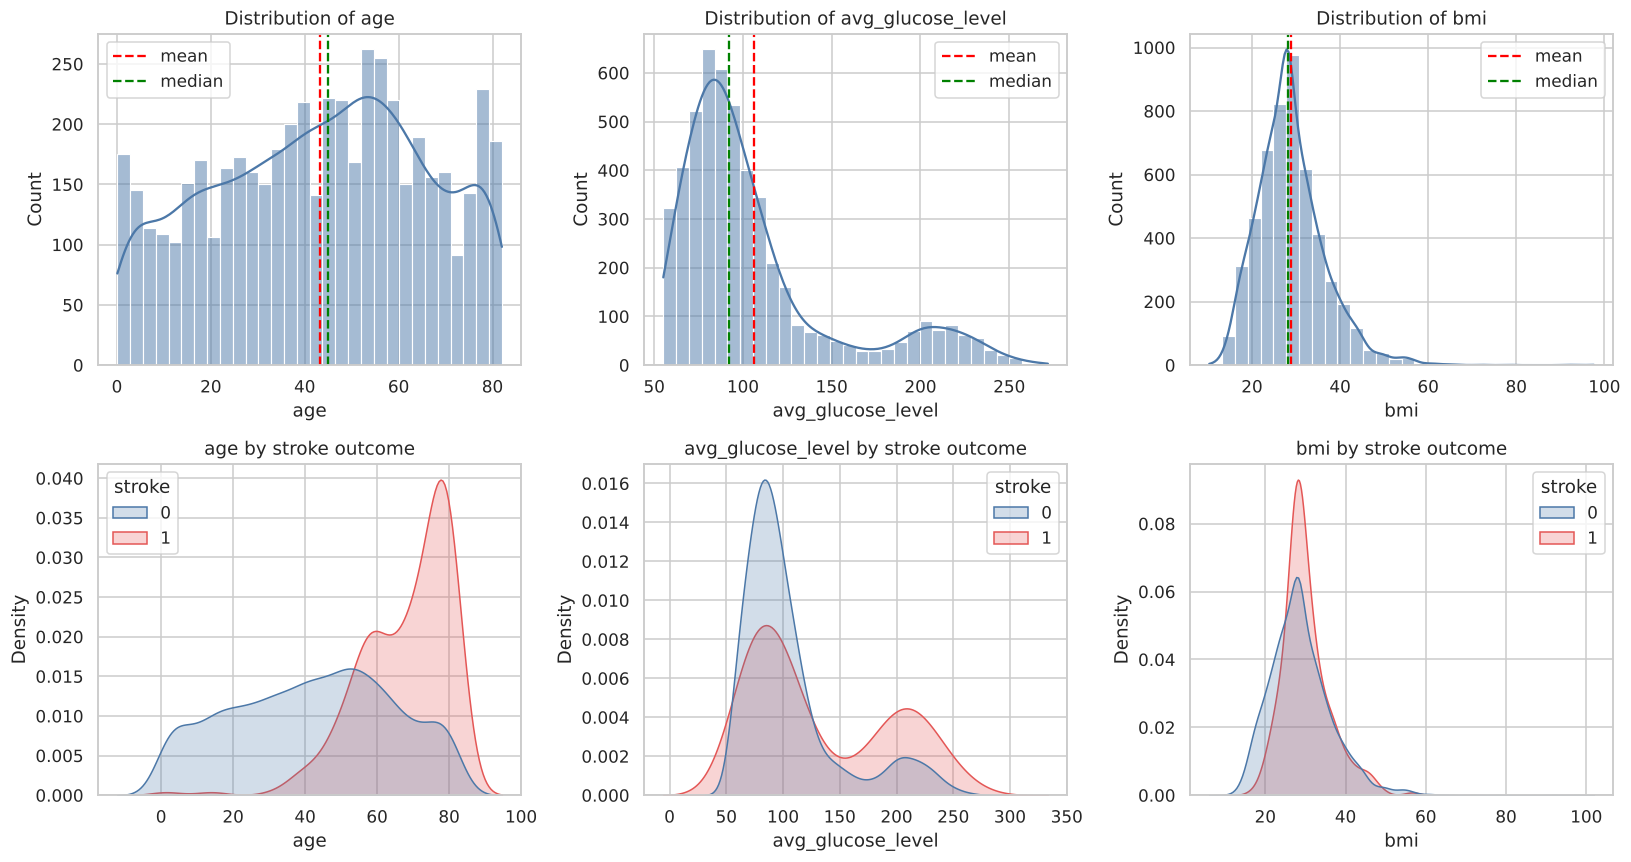

In [8]:
df_eda = df.copy()
df_eda['bmi'] = df_eda['bmi'].fillna(df_eda['bmi'].median())   # for plotting only

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, c in enumerate(NUM_COLS):
    sns.histplot(df_eda[c], kde=True, bins=30, ax=ax[0, j], color='#4C78A8')
    ax[0, j].axvline(df_eda[c].mean(), color='red', ls='--', label='mean')
    ax[0, j].axvline(df_eda[c].median(), color='green', ls='--', label='median')
    ax[0, j].set_title(f'Distribution of {c}'); ax[0, j].legend()
    sns.kdeplot(data=df_eda, x=c, hue=TARGET, common_norm=False, fill=True, ax=ax[1, j],
                palette=['#4C78A8', '#E45756'])
    ax[1, j].set_title(f'{c} by stroke outcome')
savefig('02_numeric_distributions')

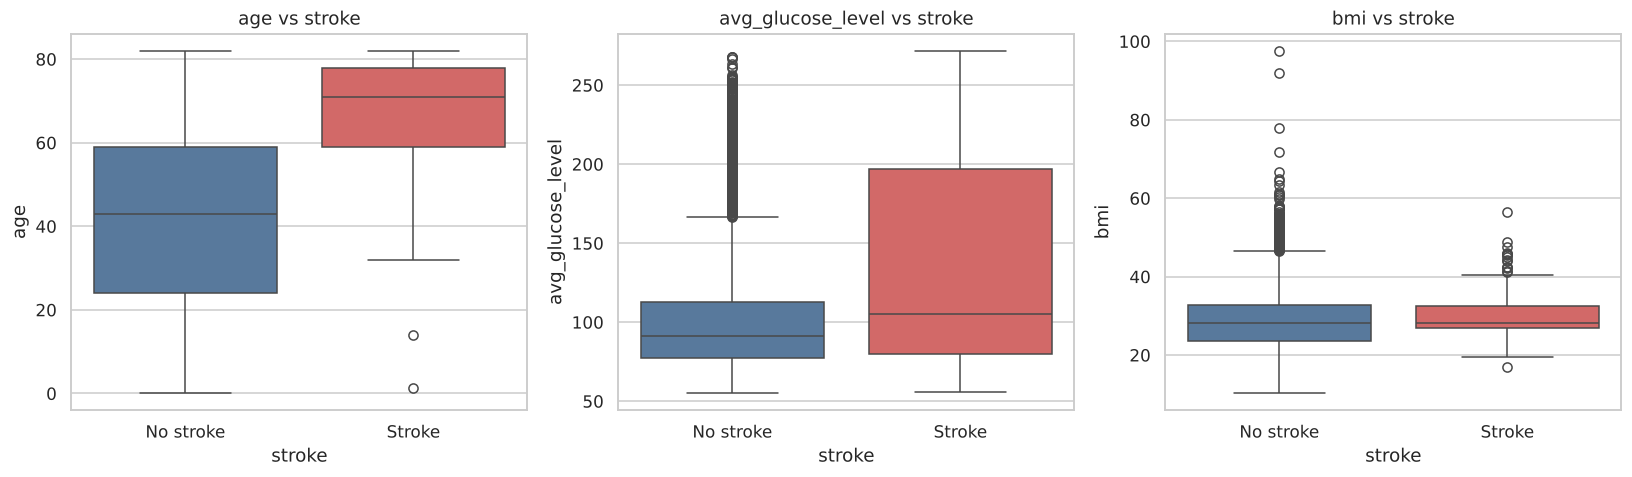

          age        avg_glucose_level            bmi       
         mean median              mean  median   mean median
stroke                                                      
0       41.97   43.0            104.79   91.46  28.80   28.1
1       67.73   71.0            132.54  105.22  30.09   28.1


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for j, c in enumerate(NUM_COLS):
    sns.boxplot(data=df_eda, x=TARGET, y=c, ax=ax[j], palette=['#4C78A8', '#E45756'])
    ax[j].set_title(f'{c} vs stroke'); ax[j].set_xticklabels(['No stroke', 'Stroke'])
savefig('03_boxplots_by_stroke')

print(df_eda.groupby(TARGET)[NUM_COLS].agg(['mean', 'median']).round(2))

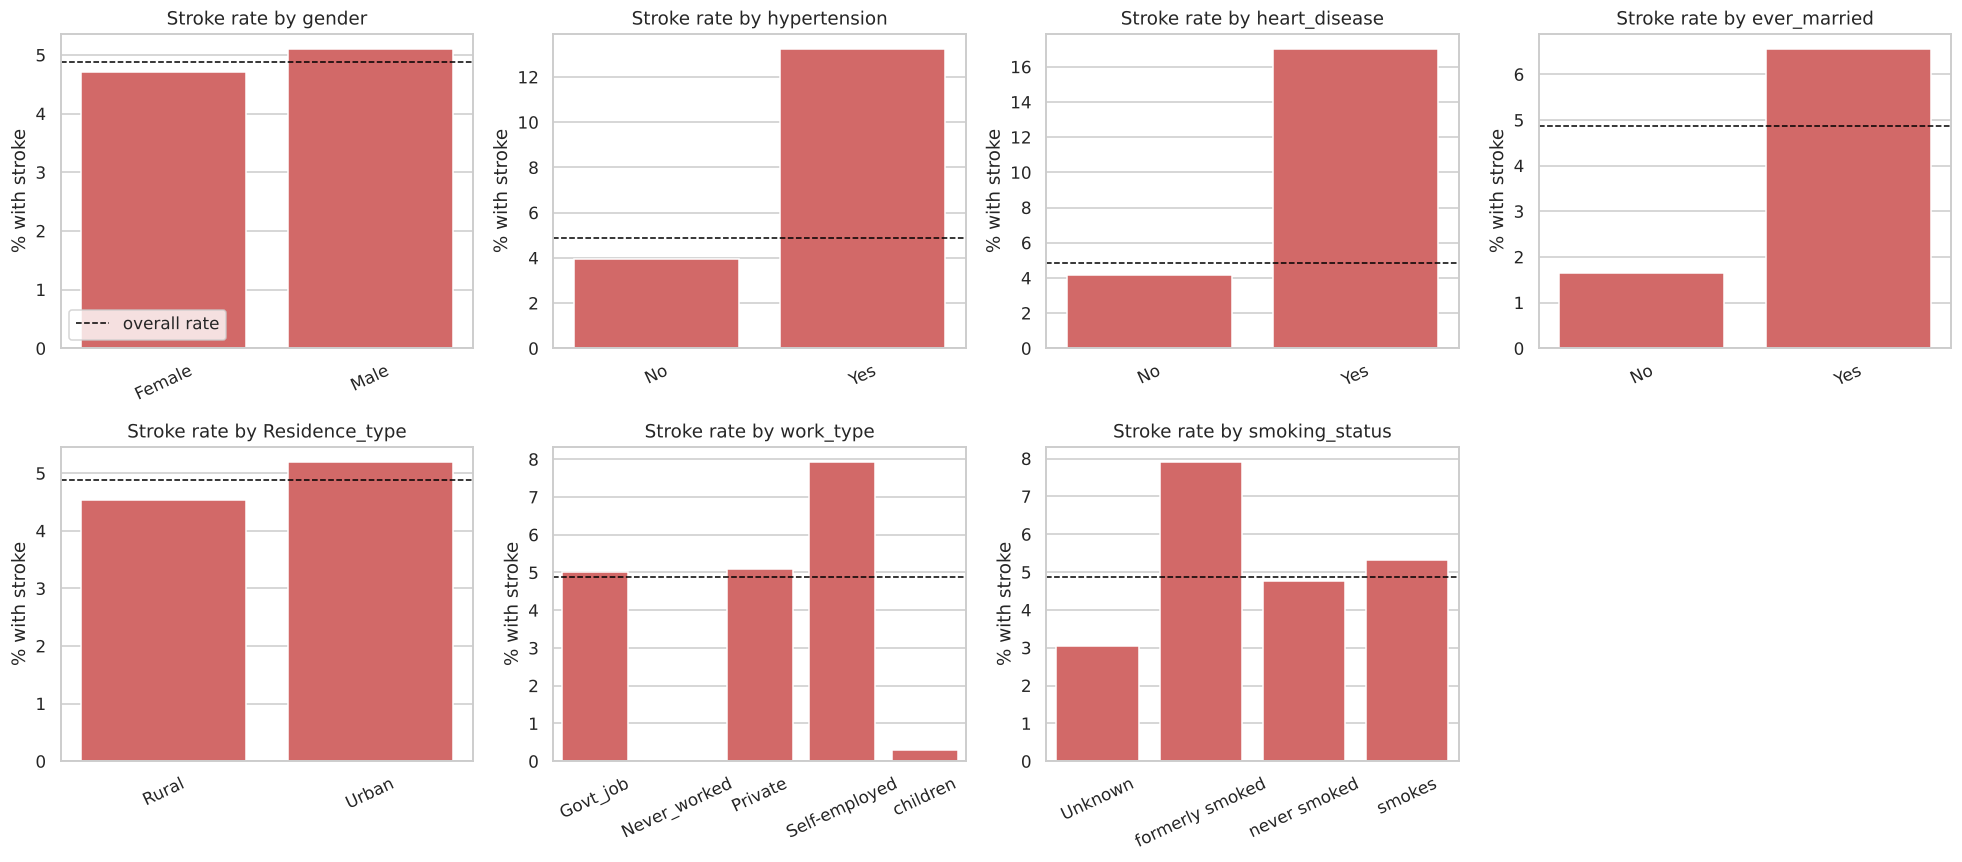

In [10]:
cat_view = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'work_type', 'smoking_status']
labels = {'gender': {0: 'Female', 1: 'Male'}, 'ever_married': {0: 'No', 1: 'Yes'},
          'Residence_type': {0: 'Rural', 1: 'Urban'}, 'hypertension': {0: 'No', 1: 'Yes'},
          'heart_disease': {0: 'No', 1: 'Yes'}}
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for i, c in enumerate(cat_view):
    rate = df.groupby(c)[TARGET].mean().mul(100)
    rate.index = [labels.get(c, {}).get(k, k) for k in rate.index]
    sns.barplot(x=rate.index, y=rate.values, ax=axes[i], color='#E45756')
    axes[i].axhline(df[TARGET].mean() * 100, color='black', ls='--', lw=1, label='overall rate')
    axes[i].set_title(f'Stroke rate by {c}'); axes[i].set_ylabel('% with stroke'); axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=25)
axes[0].legend()
axes[7].axis('off')
savefig('04_stroke_rate_by_category')

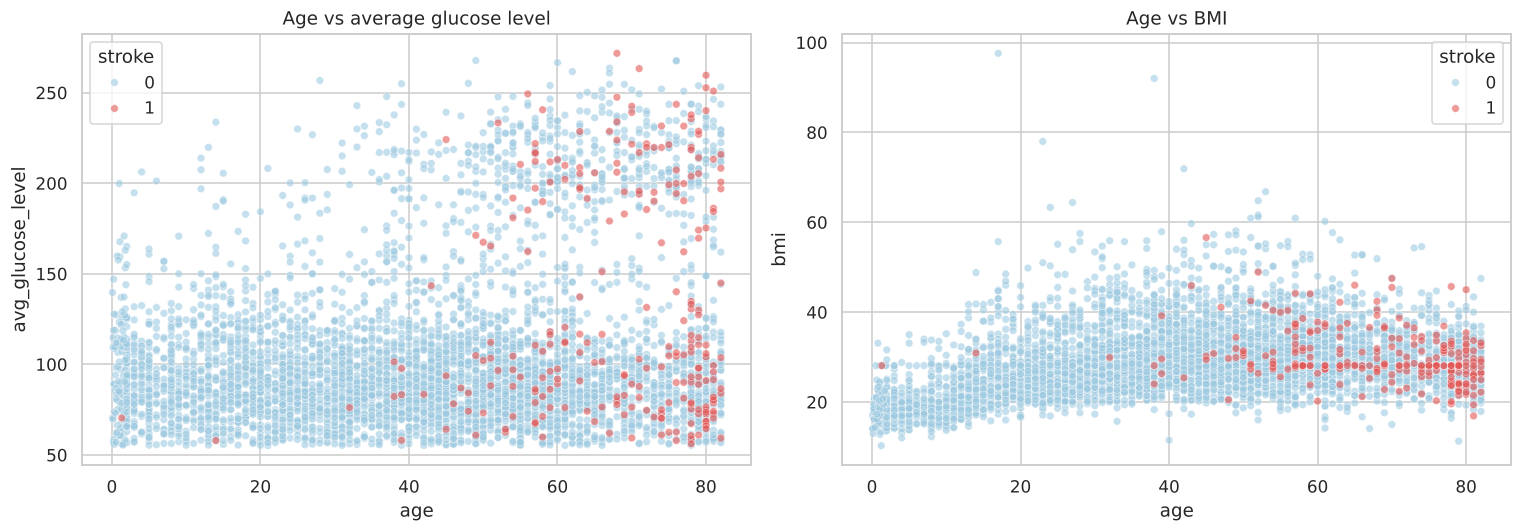

Stroke rate (%) by age band:
       count  strokes  rate_%
age                          
<18      856        2    0.23
18-39   1313        6    0.46
40-59   1564       60    3.84
60-69    621       47    7.57
70+      755      134   17.75


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = df_eda.sort_values(TARGET)   # draw stroke points last so they stay visible
sns.scatterplot(data=order, x='age', y='avg_glucose_level', hue=TARGET, palette=['#9ecae1', '#E45756'],
                alpha=0.6, s=25, ax=ax[0])
ax[0].set_title('Age vs average glucose level')
sns.scatterplot(data=order, x='age', y='bmi', hue=TARGET, palette=['#9ecae1', '#E45756'],
                alpha=0.6, s=25, ax=ax[1])
ax[1].set_title('Age vs BMI')
savefig('05_scatterplots')

# stroke rate by age band
bands = pd.cut(df.age, [0, 18, 40, 60, 70, 100], labels=['<18', '18-39', '40-59', '60-69', '70+'], right=False)
print('Stroke rate (%) by age band:')
print(df.groupby(bands, observed=True)[TARGET].agg(['count', 'sum', lambda s: round(s.mean() * 100, 2)])
        .rename(columns={'sum': 'strokes', '<lambda_0>': 'rate_%'}))

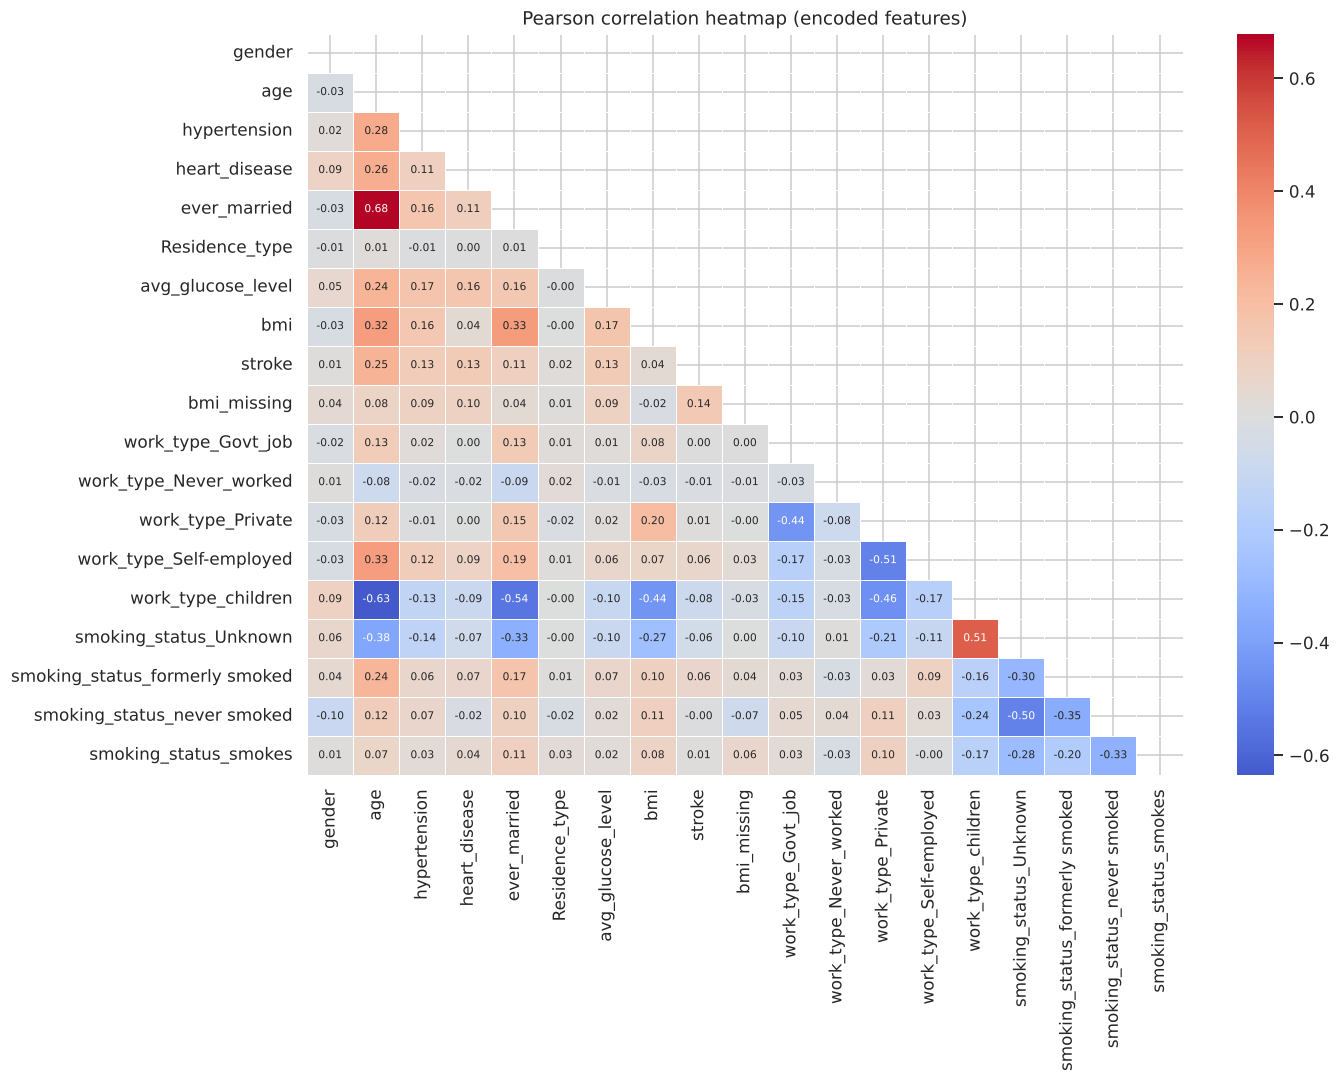

Correlation of each feature with stroke:
age                               0.245
bmi_missing                       0.141
heart_disease                     0.135
avg_glucose_level                 0.132
hypertension                      0.128
ever_married                      0.108
smoking_status_formerly smoked    0.065
work_type_Self-employed           0.062
bmi                               0.036
Residence_type                    0.015
work_type_Private                 0.012
gender                            0.009
smoking_status_smokes             0.009
work_type_Govt_job                0.003
smoking_status_never smoked      -0.004
work_type_Never_worked           -0.015
smoking_status_Unknown           -0.056
work_type_children               -0.084
Name: stroke, dtype: float64


In [12]:
enc = pd.get_dummies(df_eda, columns=CAT_COLS, dtype=int)
corr = enc.corr(method='pearson')

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.4,
            annot_kws={'size': 7}, ax=ax)
ax.set_title('Pearson correlation heatmap (encoded features)')
savefig('06_correlation_heatmap')

print('Correlation of each feature with stroke:')
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

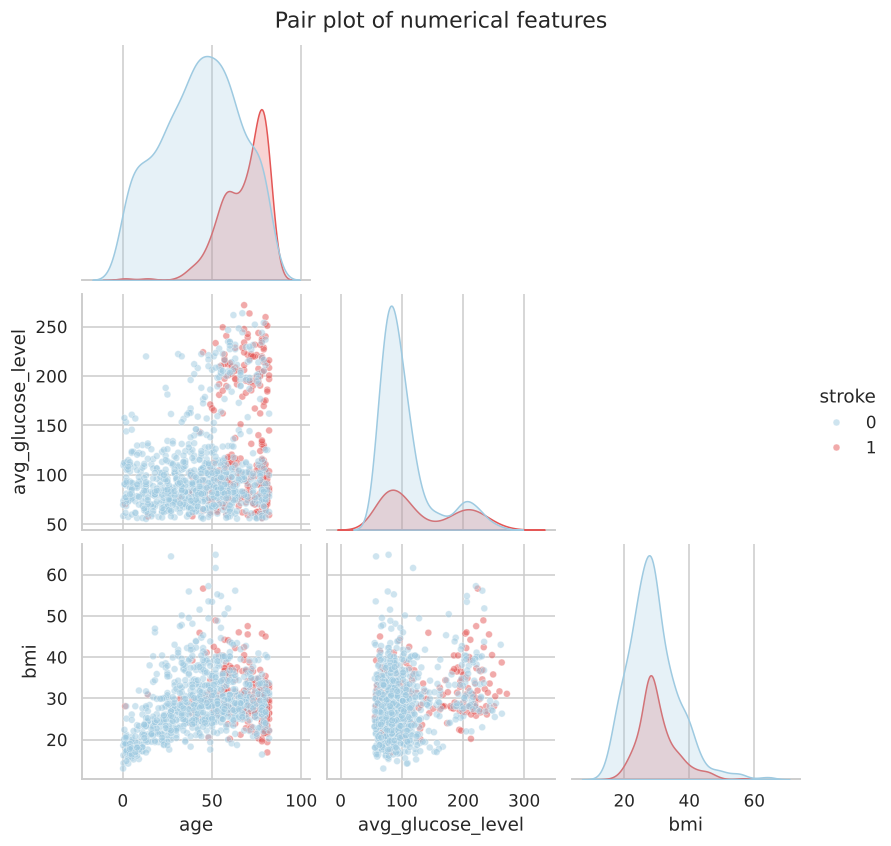

In [13]:
# All stroke cases + a random sample of non-stroke cases so both classes are visible
sample = pd.concat([df_eda[df_eda[TARGET] == 1],
                    df_eda[df_eda[TARGET] == 0].sample(800, random_state=SEED)])
g = sns.pairplot(sample[NUM_COLS + [TARGET]], hue=TARGET, palette=['#9ecae1', '#E45756'],
                 diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20}, corner=True)
g.fig.suptitle('Pair plot of numerical features', y=1.02)
g.savefig('figures/07_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

### EDA observations
1. **Severe class imbalance** - only 4.87% of patients had a stroke. A model that always answers "no stroke" would already be 95% accurate, so accuracy is not a useful headline metric here.
2. **Age is by far the strongest signal.** Stroke patients have a mean age of **67.7** vs **42.0** for the rest. The stroke rate climbs from 0.23% (under 18) and 0.46% (18-39) to 3.84% (40-59), 7.57% (60-69) and **17.75% (70+)**.
3. **Glucose** - patients with stroke have a higher mean average glucose (132.5 vs 104.8) and a clearly heavier right tail; the glucose distribution is right-skewed (skewness 1.57) and a visible cluster above ~200 has many strokes.
4. **BMI** differs little between the groups (mean 30.5 vs 28.8) - it is a weak predictor on its own.
5. **Hypertension and heart disease** each raise the observed stroke rate roughly three- to four-fold (about 13% and 17% vs about 4%).
6. `ever_married`, `work_type = Self-employed` and `smoking_status = formerly smoked` look "risky", but these largely reflect **age** (older people are more often married, self-employed or ex-smokers). `smoking_status = Unknown` and `work_type = children` have low rates because they contain many young people.
7. **Gender and residence type** show almost no difference.
8. **Correlation heatmap** - correlations with `stroke` are all modest (age 0.245, heart disease 0.135, glucose 0.132, hypertension 0.128, BMI 0.036), which signals that no single variable separates the classes and that a good model will be only moderately accurate. `age` also correlates with BMI (0.32), hypertension (0.28) and heart disease (0.26), confirming that age is entangled with the other risk factors.
9. **Pair plot / scatter plots** - strokes (red) concentrate in the top-right: older age combined with higher glucose. Younger patients almost never have a stroke whatever their glucose or BMI.

---
## D. Statistical Analysis
For the numerical variables (`age`, `avg_glucose_level`, `bmi`) we compute the range, interquartile range (IQR), mean absolute deviation (MAD), variance, standard deviation and the Pearson correlation coefficient (PCC), and then detect outliers with the IQR rule and the Z-score rule (boxplots were shown in Section C).

In [14]:
def describe_spread(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({
        'mean': s.mean(), 'median': s.median(),
        'range': s.max() - s.min(),
        'IQR': q3 - q1,
        'MAD (mean abs. deviation)': (s - s.mean()).abs().mean(),
        'variance': s.var(ddof=1),
        'std dev': s.std(ddof=1),
        'skewness': s.skew(),
    })

stats_tbl = pd.DataFrame({c: describe_spread(df[c]) for c in NUM_COLS}).T.round(3)
display(stats_tbl)
stats_tbl.to_csv('outputs/descriptive_statistics.csv')

# The same measures split by outcome
by_class = {}
for c in NUM_COLS:
    for k, name in [(0, 'no stroke'), (1, 'stroke')]:
        by_class[(c, name)] = describe_spread(df.loc[df[TARGET] == k, c])
display(pd.DataFrame(by_class).T.round(3))

,mean,median,range,IQR,MAD (mean abs. deviation),variance,std dev,skewness
age,43.230,45.00,81.92,36.00,19.117,511.374,22.614,-0.137
avg_glucose_level,106.140,91.88,216.62,36.85,33.054,2050.732,45.285,1.573
bmi,28.895,28.10,87.30,9.60,5.977,61.690,7.854,1.055


mean   median   range     IQR  \
age               no stroke   41.975   43.000   81.92   35.00   
                  stroke      67.728   71.000   80.68   19.00   
avg_glucose_level no stroke  104.788   91.465  212.64   35.68   
                  stroke     132.545  105.220  215.63  116.92   
bmi               no stroke   28.824   28.000   87.30    9.70   
                  stroke      30.471   29.700   39.70    7.30   

                             MAD (mean abs. deviation)  variance  std dev  \
age               no stroke                     18.818   496.980   22.293   
                  stroke                        10.285   161.987   12.727   
avg_glucose_level no stroke                     31.610  1922.568   43.847   
                  stroke                        55.748  3834.217   61.921   
bmi               no stroke                      6.020    62.546    7.909   
                  stroke                         4.847    40.062    6.329   

                             skewness  
age               no stroke    -0.092  
                  stroke       -1.356  
avg_glucose_level no stroke     1.639  
                  stroke        0.557  
bmi               no stroke     1.069  
                  stroke        0.893

In [15]:
# Pearson correlation matrix of the numerical variables (+ target)
pcc_cols = NUM_COLS + ['hypertension', 'heart_disease', TARGET]
pcc = df_eda[pcc_cols].corr(method='pearson').round(3)
display(pcc)

# Pearson r with p-value against the target
rows = []
for c in NUM_COLS + ['hypertension', 'heart_disease']:
    r, p = stats.pearsonr(df_eda[c], df_eda[TARGET])
    rows.append({'feature': c, 'pearson_r': round(r, 4), 'p_value': p,
                 'significant (p<0.05)': p < 0.05})
display(pd.DataFrame(rows))

r_ab, p_ab = stats.pearsonr(df_eda['age'], df_eda['bmi'])
print(f'age vs bmi: r = {r_ab:.3f} (p = {p_ab:.2e})')

,age,avg_glucose_level,bmi,hypertension,heart_disease,stroke
age,1.000,0.238,0.324,0.276,0.264,0.245
avg_glucose_level,0.238,1.000,0.167,0.175,0.162,0.132
bmi,0.324,0.167,1.000,0.158,0.037,0.036
hypertension,0.276,0.175,0.158,1.000,0.108,0.128
heart_disease,0.264,0.162,0.037,0.108,1.000,0.135
stroke,0.245,0.132,0.036,0.128,0.135,1.000


,feature,pearson_r,p_value,significant (p<0.05)
0,age,0.2452,7.435469e-71,True
1,avg_glucose_level,0.1320,2.705303e-21,True
2,bmi,0.0361,9.914907e-03,True
3,hypertension,0.1279,4.441473e-20,True
4,heart_disease,0.1349,3.506802e-22,True


age vs bmi: r = 0.324 (p = 2.38e-125)


In [16]:
rows = []
for c in NUM_COLS:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = (s < lo) | (s > hi)
    z = np.abs(stats.zscore(s))
    z_mask = z > 3
    rows.append({'feature': c, 'IQR lower': round(lo, 2), 'IQR upper': round(hi, 2),
                 'IQR outliers': int(iqr_mask.sum()), 'IQR outliers %': round(iqr_mask.mean() * 100, 2),
                 '|z|>3 outliers': int(z_mask.sum()), '|z|>3 %': round(z_mask.mean() * 100, 2),
                 'stroke rate among IQR outliers %': round(df.loc[s.index[iqr_mask], TARGET].mean() * 100, 2)})
out_tbl = pd.DataFrame(rows)
display(out_tbl)
out_tbl.to_csv('outputs/outlier_summary.csv', index=False)
print(f'Overall stroke rate for reference: {df[TARGET].mean() * 100:.2f}%')

,feature,IQR lower,IQR upper,IQR outliers,IQR outliers %,|z|>3 outliers,|z|>3 %,stroke rate among IQR outliers %
0,age,-29.00,115.00,0,0.00,0,0.00,NaN
1,avg_glucose_level,21.96,169.37,627,12.27,49,0.96,13.40
2,bmi,9.10,47.50,110,2.24,58,1.18,1.82


Overall stroke rate for reference: 4.87%


### Statistical observations
| Variable | Mean | Median | Range | IQR | MAD | Variance | Std. dev. |
|---|---|---|---|---|---|---|---|
| age | 43.23 | 45.00 | 81.92 | 36.00 | 19.12 | 511.37 | 22.61 |
| avg_glucose_level | 106.14 | 91.88 | 216.62 | 36.85 | 33.05 | 2050.73 | 45.29 |
| bmi | 28.90 | 28.10 | 87.30 | 9.60 | 5.98 | 61.69 | 7.85 |

* **Age** is almost symmetric (skewness -0.14) and widely spread. **Glucose** (skew 1.57) and **BMI** (skew 1.06) are right-skewed, with the mean pulled above the median.
* **Pearson correlation with stroke** (all significant at p < 0.05): age **r = 0.245**, heart disease 0.135, glucose 0.132, hypertension 0.128, BMI 0.036. The relationships are weak individually, even though they are statistically significant with n = 5,109.
* **Outliers:** age has none. Glucose has **627 IQR outliers (12.3%)** but only **49 with |z| > 3 (1.0%)**; BMI has 110 IQR outliers (2.2%) and 58 with |z| > 3 (1.2%). The two rules disagree on glucose because its distribution is skewed (the Z-score assumes symmetry).
* The stroke rate among glucose "outliers" is **13.4%** - nearly three times the average - so these points are signal, not noise. They are therefore **kept**.

---
## E. Model Training
### The assigned models
**AdaBoost (Adaptive Boosting).** Builds an ensemble of *weak learners* (here shallow decision trees) one after another. After each round, training samples that were misclassified get a **higher weight**, so the next tree concentrates on the hard cases. Each tree receives a vote strength that grows as its weighted error shrinks, and the final prediction is a weighted vote of all trees.

**XGBoost (Extreme Gradient Boosting).** Also adds trees sequentially, but each new tree is fitted to the **gradient of the loss** (here log loss) of the current ensemble, using first- and second-order information. It adds regularisation (L1/L2 penalties, `gamma`, `min_child_weight`), shrinkage (`learning_rate`), row/column subsampling and a built-in way to up-weight the rare class (`scale_pos_weight`), which makes it well suited to imbalanced tabular data.

### Set-up
* **Split:** 80% training / 20% test, **stratified** on the target so both parts keep the 4.9% stroke rate.
* **Imbalance:** XGBoost uses `scale_pos_weight` (searched); AdaBoost uses a class-balanced base tree.
* **Hyper-parameter tuning:** `RandomizedSearchCV`, 5-fold stratified cross-validation, scored by **ROC-AUC** (a threshold-free ranking metric, appropriate for imbalanced data). The test set is never used for tuning.
* **Baselines** with default settings are trained first to show why tuning and a threshold are needed.

In [17]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Stroke share  train: %.2f%%   test: %.2f%%' % (y_train.mean() * 100, y_test.mean() * 100))

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
SPW = neg / pos
print(f'Training class counts: {neg} no-stroke / {pos} stroke  -> scale_pos_weight = {SPW:.2f}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Show what the model actually receives
Xt_preview = preprocessor.fit_transform(X_train)
print('\nFeatures after preprocessing:', list(Xt_preview.columns))
display(Xt_preview.head())

Train: (4087, 11)  Test: (1022, 11)
Stroke share  train: 4.87%   test: 4.89%
Training class counts: 3888 no-stroke / 199 stroke  -> scale_pos_weight = 19.54

Features after preprocessing: ['age', 'avg_glucose_level', 'bmi', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'gender', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'bmi_missing']


,age,avg_glucose_level,bmi,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,gender,hypertension,heart_disease,ever_married,Residence_type,bmi_missing
845,0.209397,-0.821221,0.549234,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,0,0,1,1,0
3744,-0.629845,-0.485884,-0.988900,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,0,0,0,1,0
4183,-0.364822,0.302317,-0.769166,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,0,0,1,0,0
3409,-0.232310,0.062342,0.497532,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1,0,0,1,0,0
284,-1.292405,-0.527297,0.355351,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0,0,0,1,0


In [18]:
def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'ROC-AUC': roc_auc_score(y_true, proba),
            'PR-AUC': average_precision_score(y_true, proba)}

# Baselines: default settings, NO imbalance handling
ada_base = Pipeline([('prep', preprocessor),
                     ('clf', AdaBoostClassifier(random_state=SEED))])
xgb_base = Pipeline([('prep', preprocessor),
                     ('clf', XGBClassifier(random_state=SEED, eval_metric='logloss', n_jobs=-1))])

baseline_rows = {}
for name, m in [('AdaBoost (default)', ada_base), ('XGBoost (default)', xgb_base)]:
    m.fit(X_train, y_train)
    baseline_rows[name] = evaluate(y_test, m.predict_proba(X_test)[:, 1])
baseline_df = pd.DataFrame(baseline_rows).T.round(4)
display(baseline_df)

majority = max(y_test.mean(), 1 - y_test.mean())
print(f'\nAccuracy of always predicting "no stroke": {majority:.4f}')
print('=> accuracy alone is misleading on this dataset; recall, F1, PR-AUC and ROC-AUC matter.')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
AdaBoost (default),0.9511,0.5000,0.02,0.0385,0.8162,0.1720
XGBoost (default),0.9364,0.1053,0.04,0.0580,0.7745,0.1665



Accuracy of always predicting "no stroke": 0.9511
=> accuracy alone is misleading on this dataset; recall, F1, PR-AUC and ROC-AUC matter.


### Hyper-parameter tuning
The baselines reach ~95% accuracy but detect only 1-2 of the 50 test strokes - they have learned to say "no stroke". We now tune each model with cross-validation. For XGBoost the learning rate is searched from 0.03 upwards so that every candidate can converge in a sensible number of rounds.

In [19]:
import time

# ---------------- AdaBoost ----------------
ada_pipe = Pipeline([('prep', preprocessor),
                     ('clf', AdaBoostClassifier(
                         estimator=DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
                         random_state=SEED))])
ada_space = {
    'clf__n_estimators': [50, 100, 150, 200, 300, 400],
    'clf__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.3, 0.5, 1.0],
    'clf__estimator__max_depth': [1, 2, 3],
    'clf__estimator__min_samples_leaf': [1, 5, 20, 50],
}
t0 = time.time()
ada_search = RandomizedSearchCV(ada_pipe, ada_space, n_iter=30, scoring='roc_auc', cv=cv,
                                random_state=SEED, n_jobs=-1, refit=True)
ada_search.fit(X_train, y_train)
print(f'AdaBoost tuned in {time.time() - t0:.0f}s | best CV ROC-AUC = {ada_search.best_score_:.4f}')
print('Best params:', {k.replace('clf__', ''): v for k, v in ada_search.best_params_.items()})

# ---------------- XGBoost ----------------
xgb_pipe = Pipeline([('prep', preprocessor),
                     ('clf', XGBClassifier(random_state=SEED, eval_metric='logloss', n_jobs=1,
                                           tree_method='hist'))])
xgb_space = {
    'clf__n_estimators': [100, 200, 300, 500],
    'clf__learning_rate': [0.03, 0.05, 0.1, 0.2],   # >=0.03 so every candidate can actually converge
    'clf__max_depth': [2, 3, 4, 5],
    'clf__min_child_weight': [1, 3, 5, 10],
    'clf__subsample': [0.6, 0.8, 1.0],
    'clf__colsample_bytree': [0.6, 0.8, 1.0],
    'clf__gamma': [0, 0.5, 1, 2],
    'clf__reg_lambda': [1, 5, 10],
    'clf__scale_pos_weight': [1, np.sqrt(SPW), SPW],
}
t0 = time.time()
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=40, scoring='roc_auc', cv=cv,
                                random_state=SEED, n_jobs=-1, refit=True)
xgb_search.fit(X_train, y_train)
print(f'XGBoost tuned in {time.time() - t0:.0f}s | best CV ROC-AUC = {xgb_search.best_score_:.4f}')
print('Best params:', {k.replace('clf__', ''): (round(v, 3) if isinstance(v, float) else v)
                       for k, v in xgb_search.best_params_.items()})

ada_best, xgb_best = ada_search.best_estimator_, xgb_search.best_estimator_

AdaBoost tuned in 24s | best CV ROC-AUC = 0.8200
Best params: {'n_estimators': 50, 'learning_rate': 0.03, 'estimator__min_samples_leaf': 5, 'estimator__max_depth': 3}


XGBoost tuned in 11s | best CV ROC-AUC = 0.8524
Best params: {'subsample': 1.0, 'scale_pos_weight': np.float64(19.538), 'reg_lambda': 10, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.03, 'gamma': 1, 'colsample_bytree': 0.8}


---
## F. Prediction and Evaluation
Boosted models output a **probability**; turning it into a yes/no prediction needs a **decision threshold**. The default 0.5 is rarely best on imbalanced data (class weighting also shifts the probabilities upward), so the threshold is chosen from **out-of-fold predictions on the training data only** by maximising the F1-score, and then applied once to the untouched test set. Results at both the default 0.5 and the tuned threshold are reported.

AdaBoost: best F1 threshold (out-of-fold) = 0.860  (OOF F1 = 0.270)


XGBoost: best F1 threshold (out-of-fold) = 0.735  (OOF F1 = 0.299)


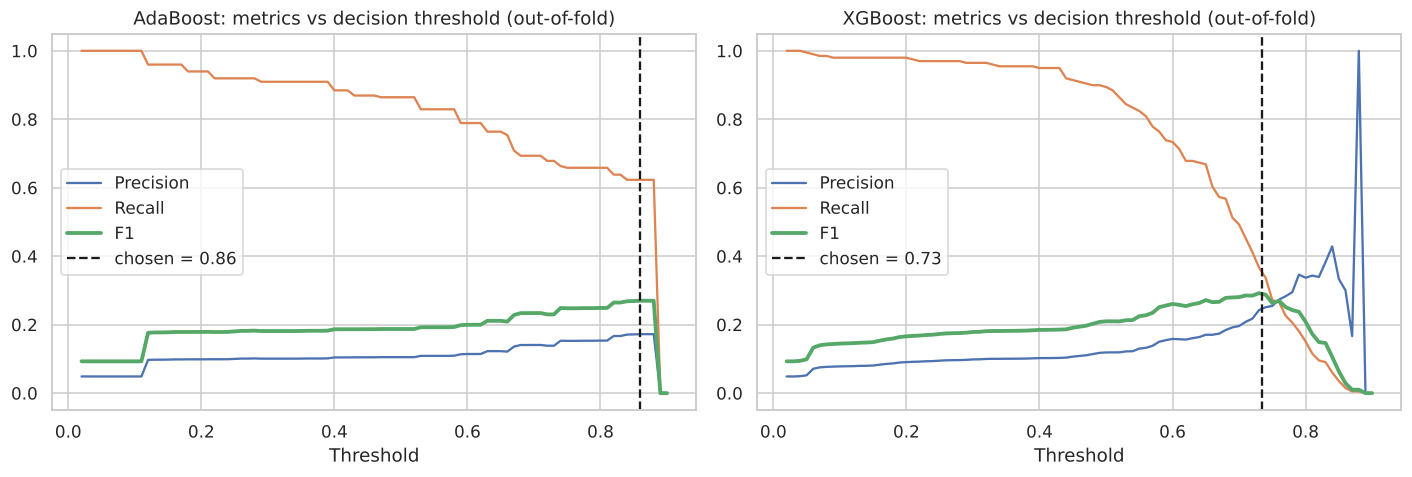

In [20]:
# Choose the decision threshold from OUT-OF-FOLD training predictions (the test set stays untouched).
def best_threshold(y_true, proba, beta=1.0):
    grid = np.linspace(0.02, 0.9, 177)
    scores = []
    for t in grid:
        p = (proba >= t).astype(int)
        pr, rc = precision_score(y_true, p, zero_division=0), recall_score(y_true, p)
        scores.append(0 if pr + rc == 0 else (1 + beta**2) * pr * rc / (beta**2 * pr + rc))
    return grid[int(np.argmax(scores))], max(scores), grid, np.array(scores)

oof = {}
for name, model in [('AdaBoost', ada_best), ('XGBoost', xgb_best)]:
    oof[name] = cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

THR = {}
for name in oof:
    t, f1_oof, grid, sc = best_threshold(y_train, oof[name])
    THR[name] = t
    print(f'{name}: best F1 threshold (out-of-fold) = {t:.3f}  (OOF F1 = {f1_oof:.3f})')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, name in zip(ax, ['AdaBoost', 'XGBoost']):
    grid = np.linspace(0.02, 0.9, 89)
    P = [precision_score(y_train, oof[name] >= t, zero_division=0) for t in grid]
    R = [recall_score(y_train, oof[name] >= t) for t in grid]
    F = [f1_score(y_train, oof[name] >= t) for t in grid]
    a.plot(grid, P, label='Precision'); a.plot(grid, R, label='Recall'); a.plot(grid, F, label='F1', lw=2.5)
    a.axvline(THR[name], color='k', ls='--', label=f'chosen = {THR[name]:.2f}')
    a.set_title(f'{name}: metrics vs decision threshold (out-of-fold)'); a.set_xlabel('Threshold'); a.legend()
savefig('08_threshold_selection')

In [21]:
proba_test = {'AdaBoost': ada_best.predict_proba(X_test)[:, 1],
              'XGBoost': xgb_best.predict_proba(X_test)[:, 1]}

rows = {}
for name in proba_test:
    rows[f'{name} (tuned, thr=0.50)'] = evaluate(y_test, proba_test[name], 0.5)
    rows[f'{name} (tuned, thr={THR[name]:.2f})'] = evaluate(y_test, proba_test[name], THR[name])
results = pd.DataFrame(rows).T.round(4)
display(results)
results.to_csv('outputs/test_metrics.csv')

for name in proba_test:
    print(f'\n===== {name} @ threshold {THR[name]:.2f} =====')
    print(classification_report(y_test, (proba_test[name] >= THR[name]).astype(int),
                                target_names=['No stroke', 'Stroke'], digits=3))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"AdaBoost (tuned, thr=0.50)",0.5675,0.0882,0.84,0.1597,0.7812,0.1475
"AdaBoost (tuned, thr=0.86)",0.8366,0.1803,0.66,0.2833,0.7812,0.1475
"XGBoost (tuned, thr=0.50)",0.6761,0.1151,0.84,0.2024,0.8389,0.2395
"XGBoost (tuned, thr=0.73)",0.9149,0.2394,0.34,0.2810,0.8389,0.2395



===== AdaBoost @ threshold 0.86 =====
              precision    recall  f1-score   support

   No stroke      0.980     0.846     0.908       972
      Stroke      0.180     0.660     0.283        50

    accuracy                          0.837      1022
   macro avg      0.580     0.753     0.596      1022
weighted avg      0.941     0.837     0.877      1022


===== XGBoost @ threshold 0.73 =====
              precision    recall  f1-score   support

   No stroke      0.965     0.944     0.955       972
      Stroke      0.239     0.340     0.281        50

    accuracy                          0.915      1022
   macro avg      0.602     0.642     0.618      1022
weighted avg      0.930     0.915     0.922      1022



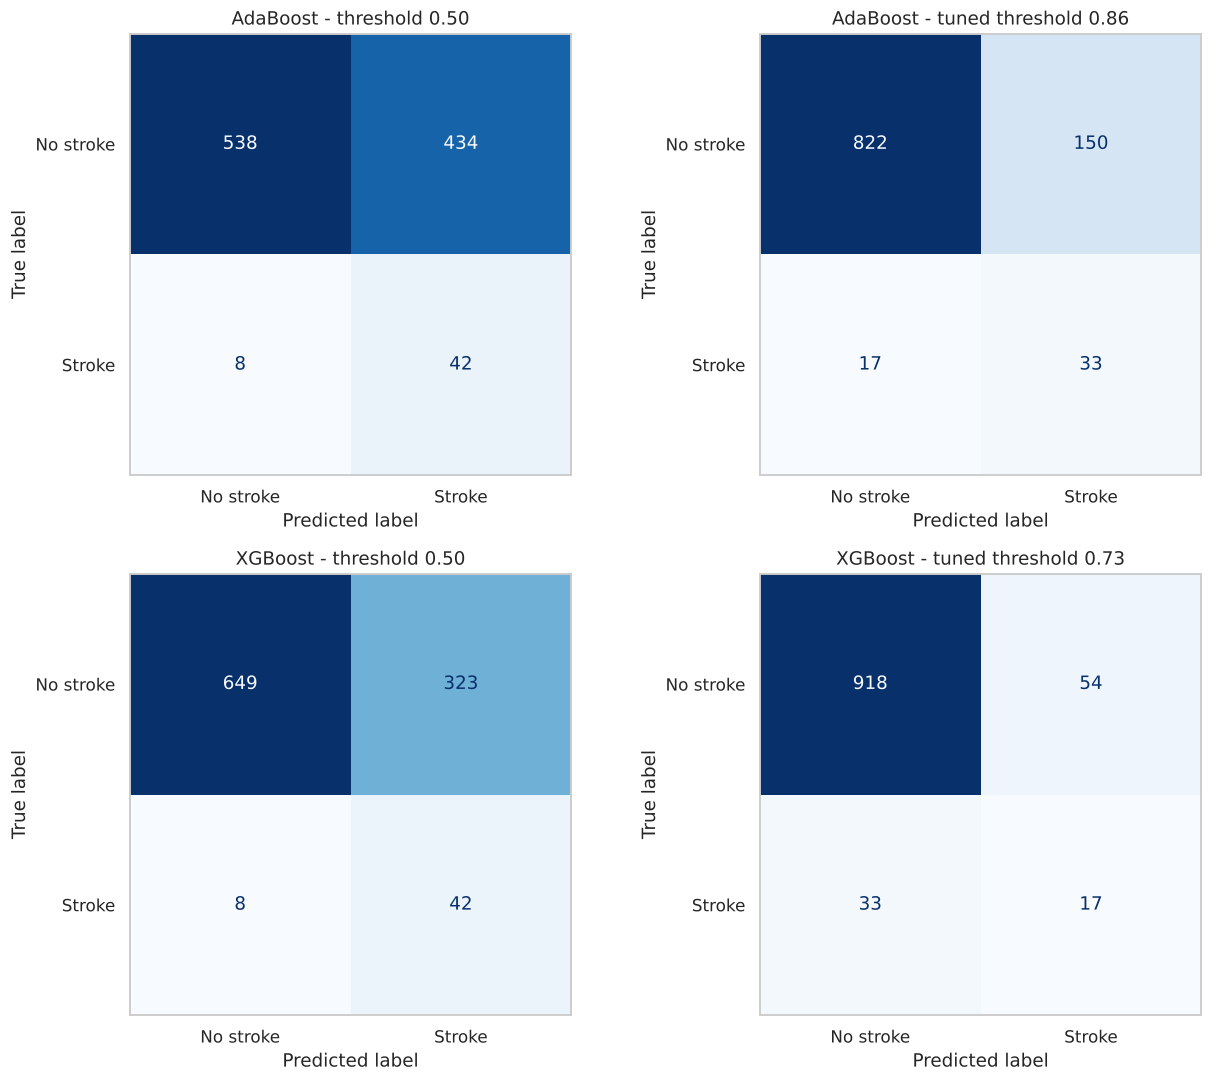

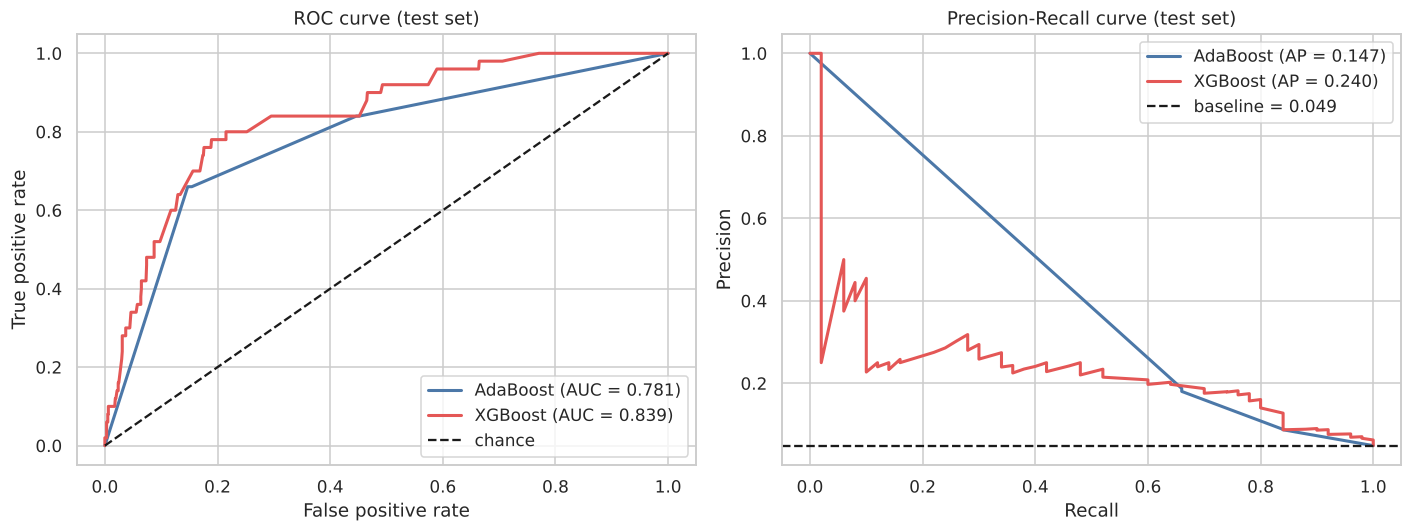

In [22]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for i, name in enumerate(['AdaBoost', 'XGBoost']):
    for j, (t, ttl) in enumerate([(0.5, 'threshold 0.50'), (THR[name], f'tuned threshold {THR[name]:.2f}')]):
        cm = confusion_matrix(y_test, (proba_test[name] >= t).astype(int))
        ConfusionMatrixDisplay(cm, display_labels=['No stroke', 'Stroke']).plot(ax=ax[i, j], cmap='Blues',
                                                                              colorbar=False, values_format='d')
        ax[i, j].set_title(f'{name} - {ttl}')
        ax[i, j].grid(False)
savefig('09_confusion_matrices')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, col in [('AdaBoost', '#4C78A8'), ('XGBoost', '#E45756')]:
    fpr, tpr, _ = roc_curve(y_test, proba_test[name])
    ax[0].plot(fpr, tpr, color=col, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, proba_test[name]):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, proba_test[name])
    ax[1].plot(rc, pr, color=col, lw=2, label=f'{name} (AP = {average_precision_score(y_test, proba_test[name]):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='chance'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curve (test set)'); ax[0].legend()
ax[1].axhline(y_test.mean(), color='k', ls='--', label=f'baseline = {y_test.mean():.3f}')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-Recall curve (test set)'); ax[1].legend()
savefig('10_roc_and_pr_curves')

In [23]:
# Cross-validated comparison on the training data (mean +/- std over 5 folds); threshold-free metrics only
rows = []
for name, model in [('AdaBoost (tuned)', ada_best), ('XGBoost (tuned)', xgb_best)]:
    row = {'model': name}
    for metric in ['roc_auc', 'average_precision']:
        s = cross_val_score(model, X_train, y_train, cv=cv, scoring=metric, n_jobs=-1)
        row[metric] = f'{s.mean():.3f} +/- {s.std():.3f}'
    rows.append(row)
cv_table = pd.DataFrame(rows).set_index('model')
display(cv_table)
cv_table.to_csv('outputs/cv_comparison.csv')

,roc_auc,average_precision
model,,
AdaBoost (tuned),0.820 +/- 0.026,0.148 +/- 0.015
XGBoost (tuned),0.852 +/- 0.030,0.237 +/- 0.043


### Evaluation results (test set: 1,022 patients, 50 strokes)
| Model | Threshold | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| AdaBoost (default) | 0.50 | 0.951 | 0.500 | 0.020 | 0.039 | 0.816 | 0.172 |
| XGBoost (default) | 0.50 | 0.936 | 0.105 | 0.040 | 0.058 | 0.775 | 0.167 |
| AdaBoost (tuned) | 0.50 | 0.568 | 0.088 | 0.840 | 0.160 | 0.781 | 0.148 |
| AdaBoost (tuned) | **0.86** | 0.837 | 0.180 | 0.660 | **0.283** | 0.781 | 0.148 |
| XGBoost (tuned) | 0.50 | 0.676 | 0.115 | 0.840 | 0.202 | **0.839** | **0.240** |
| XGBoost (tuned) | **0.73** | 0.915 | 0.239 | 0.340 | **0.281** | **0.839** | **0.240** |

**Cross-validation (training data, 5 folds):** XGBoost ROC-AUC **0.852 +/- 0.030**, average precision 0.237 +/- 0.043; AdaBoost ROC-AUC 0.820 +/- 0.026, average precision 0.148 +/- 0.015.

**Reading the results**
* **Accuracy is misleading.** The untuned models look best on accuracy (0.95) only because they almost never predict a stroke (recall 2-4%). The tuned models have *lower* accuracy but are far more useful.
* **XGBoost ranks patients better than AdaBoost** - higher ROC-AUC (0.839 vs 0.781) and PR-AUC (0.240 vs 0.148, against a no-skill baseline of 0.049), and the same ordering appears in cross-validation. With only 50 positive test cases the test-set gap is noisy, but it agrees with the cross-validated gap.
* **Precision-recall trade-off.** At threshold 0.5 both models catch 42 of 50 strokes (recall 0.84) but raise many false alarms (precision 9-12%). At the F1-optimal threshold, F1 is similar for the two models (~0.28) but they sit at different operating points: AdaBoost catches 66% of strokes at 18% precision, XGBoost catches 34% at 24% precision.
* **Which threshold to use is a clinical choice, not a statistical one.** For screening, where a missed stroke is costlier than a false alarm, a lower threshold (higher recall) is preferable; the threshold plot (Figure 08) lets the decision-maker pick the trade-off.

---
## G. Training / Evaluation Curves
Because boosting adds trees one at a time, the natural "epoch" is the **boosting round**. We plot training vs validation performance per round (using a held-out validation slice of the training data), plus learning curves that show how performance changes with the amount of training data. For the per-round plots the models are deliberately trained **longer than the selected size** (dashed line = selected size) purely to reveal where over-fitting begins.

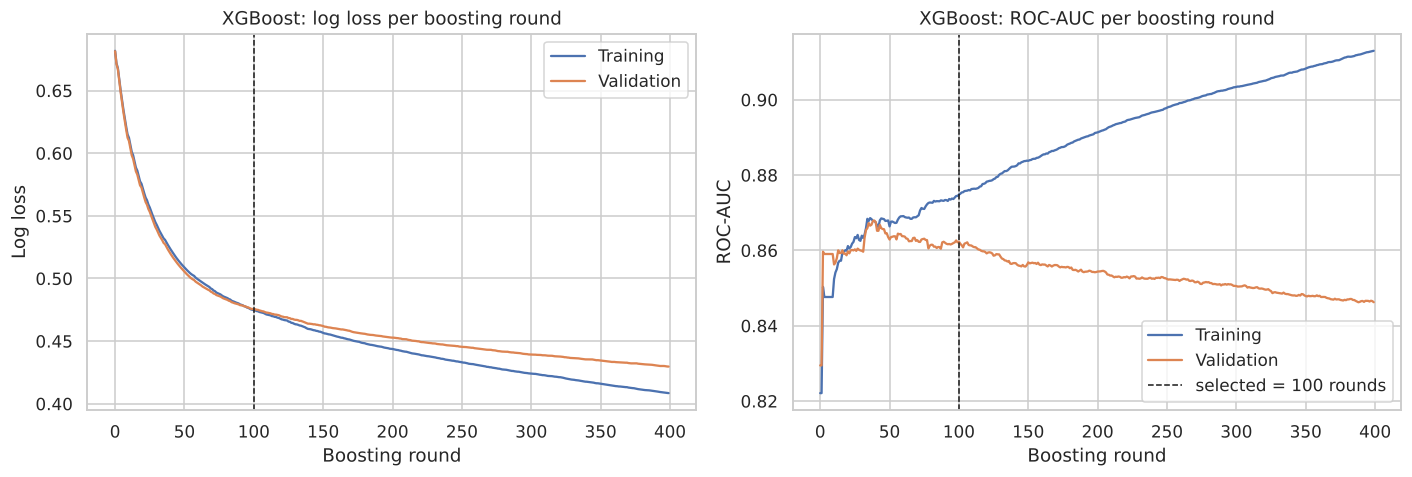

Lowest validation log loss at round 400 (0.4297); best validation AUC at round 40 (0.8679); final-round training AUC 0.9130 vs validation AUC 0.8463


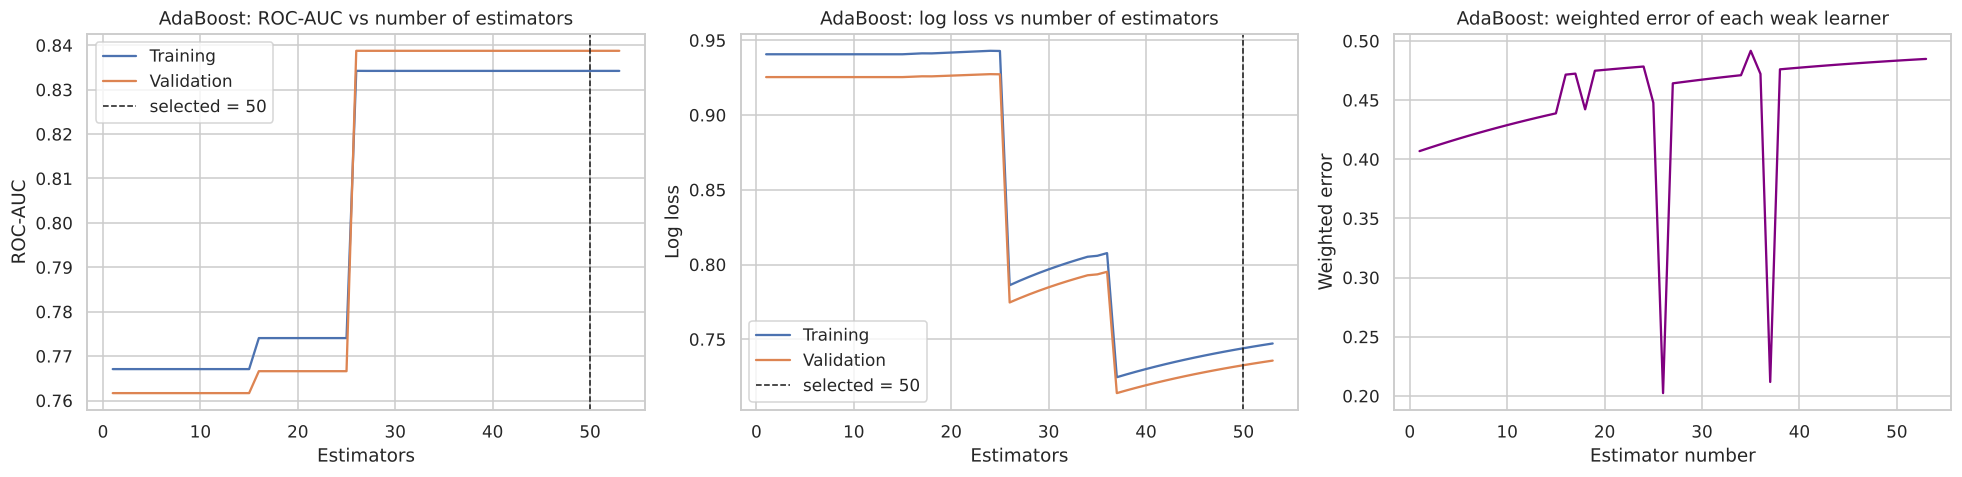

AdaBoost best validation AUC at 26 estimators (0.8388); at 53 estimators: training AUC 0.8342 vs validation AUC 0.8388


In [24]:
# --- XGBoost: training vs validation loss / AUC per boosting round ---
Xa, Xv, ya, yv = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED)
prep_c = Pipeline([('p', preprocessor)]).fit(Xa)
Xa_t, Xv_t = prep_c.transform(Xa), prep_c.transform(Xv)

xp = {k.replace('clf__', ''): v for k, v in xgb_search.best_params_.items()}
SEL_X = xp['n_estimators']          # rounds chosen by the search
xp['n_estimators'] = 400            # diagnostic only: train longer to SEE where over-fitting starts
xgb_curve = XGBClassifier(**xp, random_state=SEED, eval_metric=['logloss', 'auc'], tree_method='hist', n_jobs=-1)
xgb_curve.fit(Xa_t, ya, eval_set=[(Xa_t, ya), (Xv_t, yv)], verbose=False)
res = xgb_curve.evals_result()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(res['validation_0']['logloss'], label='Training'); ax[0].plot(res['validation_1']['logloss'], label='Validation')
ax[0].set_title('XGBoost: log loss per boosting round'); ax[0].set_xlabel('Boosting round'); ax[0].set_ylabel('Log loss'); ax[0].legend()
ax[1].plot(res['validation_0']['auc'], label='Training'); ax[1].plot(res['validation_1']['auc'], label='Validation')
ax[1].set_title('XGBoost: ROC-AUC per boosting round'); ax[1].set_xlabel('Boosting round'); ax[1].set_ylabel('ROC-AUC'); ax[1].legend()
for a in ax: a.axvline(SEL_X, color='k', ls='--', lw=1, label=f'selected = {SEL_X} rounds')
ax[1].legend()
savefig('11_xgboost_training_curves')
best_ll = int(np.argmin(res['validation_1']['logloss'])); best_auc = int(np.argmax(res['validation_1']['auc']))
print(f'Lowest validation log loss at round {best_ll + 1} ({res["validation_1"]["logloss"][best_ll]:.4f}); '
      f'best validation AUC at round {best_auc + 1} ({res["validation_1"]["auc"][best_auc]:.4f}); '
      f'final-round training AUC {res["validation_0"]["auc"][-1]:.4f} vs validation AUC {res["validation_1"]["auc"][-1]:.4f}')

# --- AdaBoost: staged training vs validation performance ---
ap = {k.replace('clf__', ''): v for k, v in ada_search.best_params_.items()}
depth, leaf = ap.pop('estimator__max_depth'), ap.pop('estimator__min_samples_leaf')
SEL_A = ap['n_estimators']          # estimators chosen by the search
ap['n_estimators'] = 300            # diagnostic only: train longer to SEE where over-fitting starts
ada_curve = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                                                class_weight='balanced', random_state=SEED),
                               random_state=SEED, **ap)
ada_curve.fit(Xa_t, ya)
tr_auc = [roc_auc_score(ya, p[:, 1]) for p in ada_curve.staged_predict_proba(Xa_t)]
va_auc = [roc_auc_score(yv, p[:, 1]) for p in ada_curve.staged_predict_proba(Xv_t)]
tr_ll = [log_loss(ya, p[:, 1]) for p in ada_curve.staged_predict_proba(Xa_t)]
va_ll = [log_loss(yv, p[:, 1]) for p in ada_curve.staged_predict_proba(Xv_t)]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(range(1, len(tr_auc) + 1), tr_auc, label='Training'); ax[0].plot(range(1, len(va_auc) + 1), va_auc, label='Validation')
ax[0].set_title('AdaBoost: ROC-AUC vs number of estimators'); ax[0].set_xlabel('Estimators'); ax[0].set_ylabel('ROC-AUC'); ax[0].legend()
ax[1].plot(range(1, len(tr_ll) + 1), tr_ll, label='Training'); ax[1].plot(range(1, len(va_ll) + 1), va_ll, label='Validation')
ax[1].set_title('AdaBoost: log loss vs number of estimators'); ax[1].set_xlabel('Estimators'); ax[1].set_ylabel('Log loss'); ax[1].legend()
n_fit = len(tr_auc)   # AdaBoost stops early once a weak learner's weighted error reaches 0.5; unused slots are padded with 1.0
ax[2].plot(range(1, n_fit + 1), ada_curve.estimator_errors_[:n_fit], color='purple')
ax[2].set_title('AdaBoost: weighted error of each weak learner'); ax[2].set_xlabel('Estimator number'); ax[2].set_ylabel('Weighted error')
for a in ax[:2]: a.axvline(SEL_A, color='k', ls='--', lw=1, label=f'selected = {SEL_A}'); a.legend()
savefig('12_adaboost_training_curves')
print(f'AdaBoost best validation AUC at {int(np.argmax(va_auc)) + 1} estimators ({max(va_auc):.4f}); '
      f'at {len(va_auc)} estimators: training AUC {tr_auc[-1]:.4f} vs validation AUC {va_auc[-1]:.4f}')

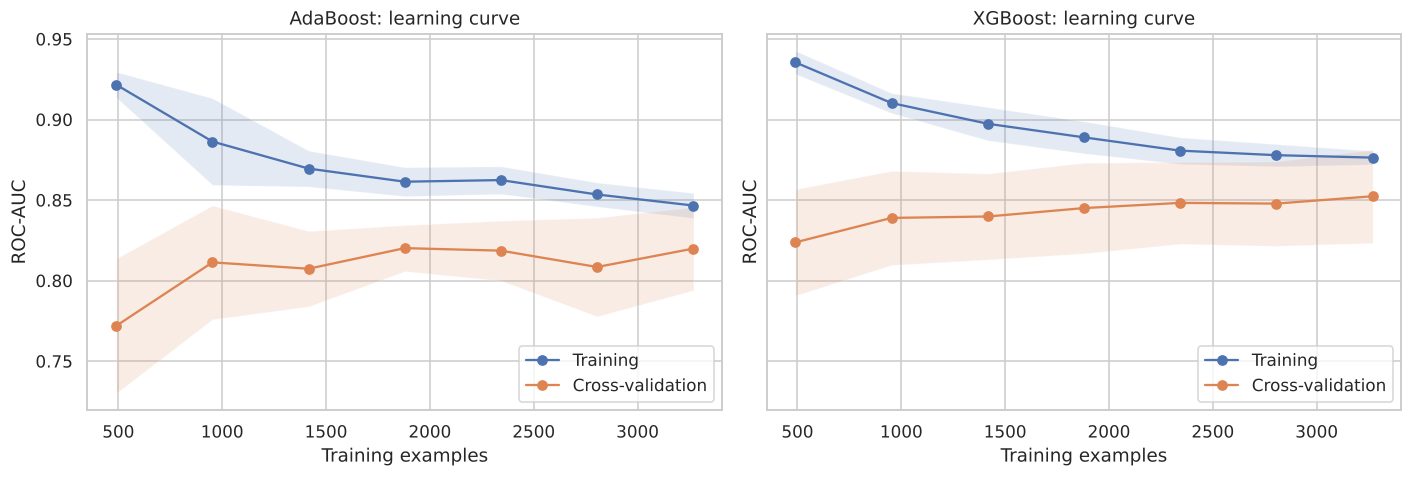

In [25]:
sizes = np.linspace(0.15, 1.0, 7)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, (name, model) in zip(ax, [('AdaBoost', ada_best), ('XGBoost', xgb_best)]):
    n, tr, va = learning_curve(model, X_train, y_train, train_sizes=sizes, cv=cv, scoring='roc_auc', n_jobs=-1,
                               random_state=SEED, shuffle=True)
    a.plot(n, tr.mean(1), 'o-', label='Training'); a.fill_between(n, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), alpha=.15)
    a.plot(n, va.mean(1), 'o-', label='Cross-validation'); a.fill_between(n, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.15)
    a.set_title(f'{name}: learning curve'); a.set_xlabel('Training examples'); a.set_ylabel('ROC-AUC'); a.legend(loc='lower right')
savefig('13_learning_curves')

### Curve observations
* **XGBoost, ROC-AUC per round:** training AUC keeps rising (0.82 -> 0.91 by round 400) while validation AUC **peaks around round 40 (0.868) and then declines** (0.846 at round 400). This is classic over-fitting: extra rounds memorise the training patients. The selected model (100 rounds, shallow depth 2, strong regularisation) stops well before the damage becomes large.
* **XGBoost, log loss per round:** it keeps falling slowly on both sets, but log loss mostly rewards confident probabilities, whereas our goal is correct *ranking* of risk, so AUC is the more relevant curve here.
* **AdaBoost:** scikit-learn stops boosting automatically once a weak learner's weighted error reaches 0.5 (the learner is no better than chance on the re-weighted data). That happened after **53 estimators**; validation AUC reaches its best (about 0.839) at about 26 estimators and then plateaus. Training and validation lines stay close, so AdaBoost is **not over-fitting - it is limited by weak signal**.
* **Learning curves:** the gap between training and cross-validation AUC shows the variance of each model; the cross-validation curve flattens at roughly 0.82-0.85, which suggests that **more patients (especially more stroke cases) and more informative features** would help more than more tuning.

---
## H. Interpretation
Feature importance is measured in two ways: the model's built-in importance, and **permutation importance on the test set** (how much ROC-AUC drops when one original feature is shuffled). Permutation importance is more trustworthy because it measures real predictive value on unseen data. Finally, the model is used as a risk-ranking tool.

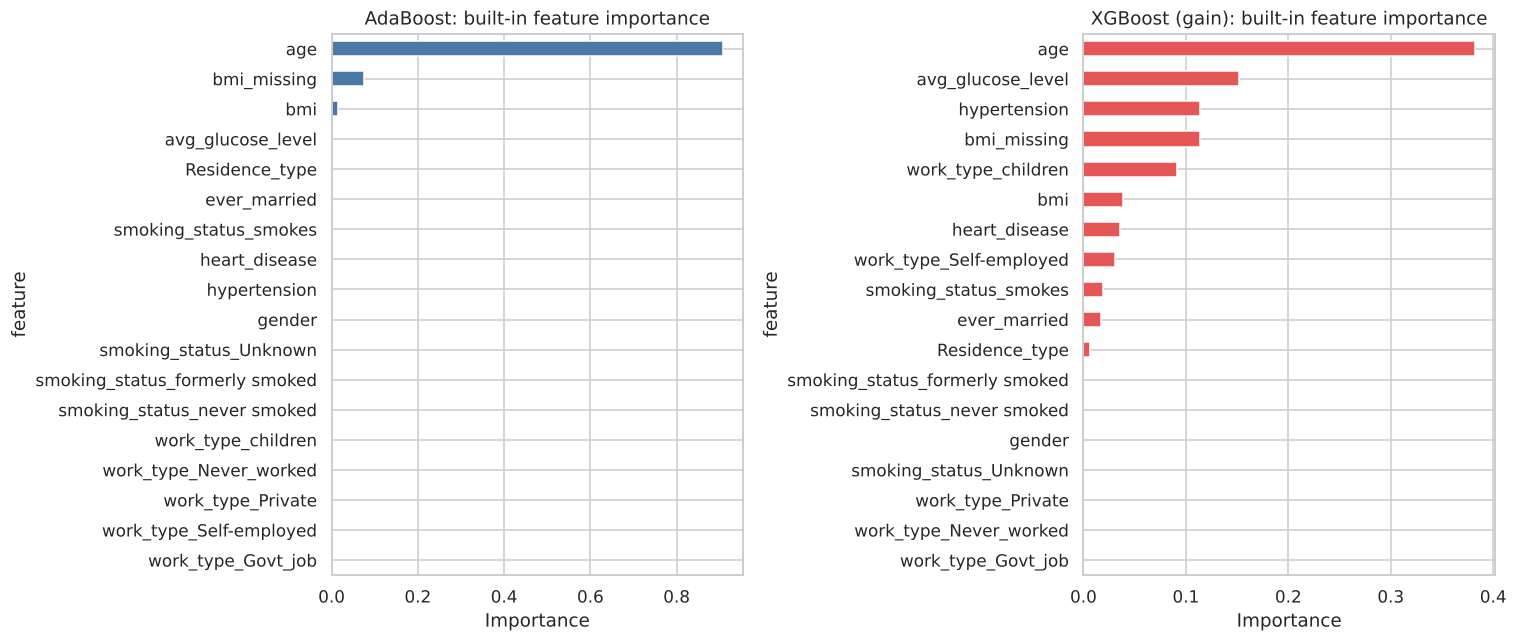

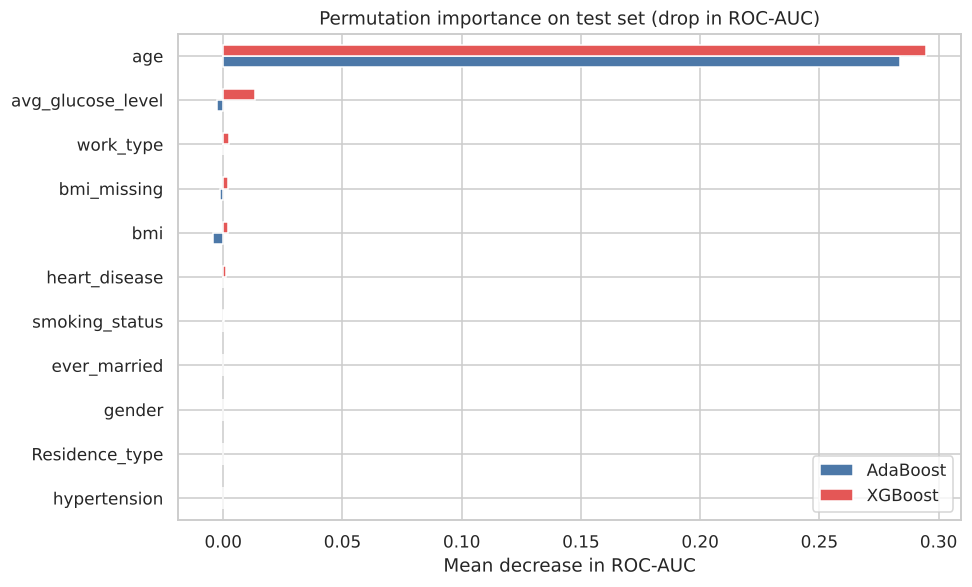

,AdaBoost,XGBoost
age,0.2837,0.2946
avg_glucose_level,-0.0028,0.0133
work_type,0.0000,0.0023
bmi_missing,-0.0012,0.0021
bmi,-0.0041,0.0021
heart_disease,0.0000,0.0012
smoking_status,0.0000,0.0004
ever_married,0.0000,0.0001
gender,0.0000,0.0000
Residence_type,0.0000,-0.0002


In [26]:
feat_names = list(ada_best.named_steps['prep'].get_feature_names_out())
imp = pd.DataFrame({
    'feature': feat_names,
    'AdaBoost': ada_best.named_steps['clf'].feature_importances_,
    'XGBoost (gain)': xgb_best.named_steps['clf'].feature_importances_,
}).set_index('feature')

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, col, color in zip(ax, ['AdaBoost', 'XGBoost (gain)'], ['#4C78A8', '#E45756']):
    imp[col].sort_values().plot.barh(ax=a, color=color)
    a.set_title(f'{col}: built-in feature importance'); a.set_xlabel('Importance')
savefig('14_feature_importance_builtin')

# Permutation importance on the TEST set, permuting the ORIGINAL columns (categoricals stay grouped)
perm_rows = {}
for name, model in [('AdaBoost', ada_best), ('XGBoost', xgb_best)]:
    pi = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
    perm_rows[name] = pd.Series(pi.importances_mean, index=X_test.columns)
perm = pd.DataFrame(perm_rows)

fig, ax = plt.subplots(figsize=(9, 5.5))
perm.sort_values('XGBoost').plot.barh(ax=ax, color=['#4C78A8', '#E45756'])
ax.set_title('Permutation importance on test set (drop in ROC-AUC)'); ax.set_xlabel('Mean decrease in ROC-AUC')
savefig('15_permutation_importance')
display(perm.sort_values('XGBoost', ascending=False).round(4))
imp.round(4).to_csv('outputs/feature_importance_builtin.csv'); perm.round(5).to_csv('outputs/permutation_importance.csv')

Model used for the risk analysis: XGBoost


,patients,strokes,observed_rate_%,lift_vs_average
risk_group,,,,
Q1 lowest,205,0,0.00,0.00
Q2,204,2,0.98,0.20
Q3,204,6,2.94,0.60
Q4,204,5,2.45,0.50
Q5 highest,205,37,18.05,3.69


The highest-risk 20% of patients contain 74% of all strokes in the test set.


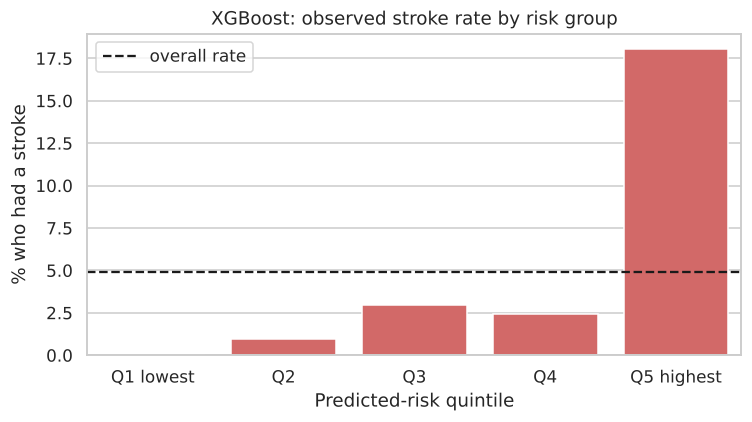

NOTE: class weighting inflates the scores, so they are a RANKING score, not a calibrated probability.


,age,hypertension,heart_disease,avg_glucose_level,model_risk_score
"Young, healthy",28,0,0,88.0,0.055
"Middle-aged, hypertensive",58,1,0,145.0,0.645
"Older, hypertension + heart disease",76,1,1,225.0,0.827


In [27]:
# Decision-support view: how well does the predicted risk rank patients?
best_name = 'XGBoost' if roc_auc_score(y_test, proba_test['XGBoost']) >= roc_auc_score(y_test, proba_test['AdaBoost']) else 'AdaBoost'
print('Model used for the risk analysis:', best_name)
p = proba_test[best_name]
risk = pd.DataFrame({'p': p, 'y': y_test.values})
risk['risk_group'] = pd.qcut(risk.p.rank(method='first'), 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])
tbl = risk.groupby('risk_group', observed=True).agg(patients=('y', 'size'), strokes=('y', 'sum'),
                                                    observed_rate=('y', 'mean'), mean_pred=('p', 'mean'))
tbl['observed_rate_%'] = (tbl.observed_rate * 100).round(2)
tbl['lift_vs_average'] = (tbl.observed_rate / y_test.mean()).round(2)
display(tbl[['patients', 'strokes', 'observed_rate_%', 'lift_vs_average']])

top = tbl.loc['Q5 highest']; share = top.strokes / tbl.strokes.sum()
print(f'The highest-risk 20% of patients contain {share:.0%} of all strokes in the test set.')

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=tbl.index.astype(str), y=tbl['observed_rate_%'], color='#E45756', ax=ax)
ax.axhline(y_test.mean() * 100, color='k', ls='--', label='overall rate')
ax.set_ylabel('% who had a stroke'); ax.set_xlabel('Predicted-risk quintile'); ax.set_title(f'{best_name}: observed stroke rate by risk group')
ax.legend()
savefig('16_risk_quintiles')

# Three illustrative patient profiles
profiles = pd.DataFrame([
    dict(gender=0, age=28, hypertension=0, heart_disease=0, ever_married=0, work_type='Private', Residence_type=1,
         avg_glucose_level=88.0, bmi=23.5, smoking_status='never smoked', bmi_missing=0),
    dict(gender=1, age=58, hypertension=1, heart_disease=0, ever_married=1, work_type='Private', Residence_type=1,
         avg_glucose_level=145.0, bmi=31.0, smoking_status='formerly smoked', bmi_missing=0),
    dict(gender=1, age=76, hypertension=1, heart_disease=1, ever_married=1, work_type='Self-employed', Residence_type=0,
         avg_glucose_level=225.0, bmi=34.0, smoking_status='smokes', bmi_missing=0),
], index=['Young, healthy', 'Middle-aged, hypertensive', 'Older, hypertension + heart disease'])
final_model = {'XGBoost': xgb_best, 'AdaBoost': ada_best}[best_name]
profiles['model_risk_score'] = final_model.predict_proba(profiles[X.columns])[:, 1].round(3)
print('NOTE: class weighting inflates the scores, so they are a RANKING score, not a calibrated probability.')
display(profiles[['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'model_risk_score']])

In [28]:
import joblib
df.to_csv('outputs/cleaned_stroke_data.csv', index=False)
joblib.dump(xgb_best, 'outputs/xgboost_pipeline.joblib')
joblib.dump(ada_best, 'outputs/adaboost_pipeline.joblib')
results.to_csv('outputs/test_metrics.csv')
json.dump({'adaboost_threshold': float(THR['AdaBoost']), 'xgboost_threshold': float(THR['XGBoost']),
           'adaboost_params': {k: (v if not hasattr(v, 'item') else v.item()) for k, v in ada_search.best_params_.items()},
           'xgboost_params': {k: (v if not hasattr(v, 'item') else float(v)) for k, v in xgb_search.best_params_.items()}},
          open('outputs/best_hyperparameters.json', 'w'), indent=2)
print('Saved cleaned data, models, metrics and hyper-parameters to ./outputs and figures to ./figures')

Saved cleaned data, models, metrics and hyper-parameters to ./outputs and figures to ./figures


### Answers to the interpretation questions

**1. What did the model learn from the data?**
Mainly one thing: **stroke risk rises sharply with age**, with glucose level adding a smaller contribution. Older patients with high glucose, hypertension or heart disease receive the highest scores; young patients receive very low scores whatever their other values.

**2. Which features were most important?**
**Age dominates**: shuffling it costs about 0.29 ROC-AUC for XGBoost (0.28 for AdaBoost). **Average glucose level** is a distant second for XGBoost (about 0.013). BMI, heart disease, hypertension, work type, smoking, gender and residence add almost nothing once age is known, because much of their effect is already explained by age.

**3. How well did the model perform?**
XGBoost reached **ROC-AUC 0.839 and PR-AUC 0.240** on the test set (AdaBoost: 0.781 and 0.148); cross-validated AUC is 0.852 for XGBoost and 0.820 for AdaBoost. That is *good at ranking* patients by risk but only *moderate at classifying* them: the best F1 is about 0.28, i.e. many false alarms for every stroke found. Ranking quality is strong: in the XGBoost risk-group table the **top 20% of patients by score contained 37 of the 50 test strokes (74%)** with an 18.1% stroke rate (3.7 times the average), while the lowest 20% contained none.

**4. What patterns were discovered?**
A steep age gradient (0.2% under 18 vs 17.8% at 70+); higher risk with hypertension, heart disease and high glucose; no meaningful gender or urban/rural effect; apparent "risk" from marital status, self-employment and past smoking is mostly an age effect; and patients with a **missing BMI had a much higher stroke rate** (19.9% vs 4.3%), probably because of how the data was collected rather than a medical reason.

**5. What limitations does the model have?**
* **Very few positive cases** (249 in total, only 50 in the test set): every metric has wide uncertainty - one more or fewer detected stroke moves recall by 2 percentage points.
* **Moderate precision:** even the best threshold gives roughly 3 false alarms for each true stroke caught.
* **Class weighting makes the scores a ranking, not a calibrated probability** - a predicted 0.65 does not mean a 65% chance of stroke.
* **Observational snapshot:** the data contains no timing (when the stroke happened relative to the measurements), so the model finds associations, not causes, and "stroke" may include past events.
* The dataset lacks key clinical predictors (blood pressure values, cholesterol, atrial fibrillation, family history, medication), and `smoking_status = Unknown` (30%) and the missing-BMI pattern are data-quality issues.
* Single data source, no external validation, so generalisation to other hospitals or populations is untested.

**6. How could the model be improved?**
Collect more stroke cases and more clinical features; try oversampling (e.g. SMOTE) or cost-sensitive learning and compare with class weighting; calibrate probabilities (Platt / isotonic); tune the threshold against an explicit cost for missed strokes vs false alarms; use repeated cross-validation to tighten the uncertainty; add features such as age-glucose interactions; compare with LightGBM/CatBoost and a logistic-regression baseline; and validate on an independent dataset.

**7. What real-world decision could be supported?**
As a **screening / triage aid**, not a diagnostic tool: rank patients by risk so that limited resources (blood-pressure and glucose checks, lifestyle counselling, referral for preventive care) are offered first to the highest-risk group. Concentrating on the top 20% would reach about three-quarters of the strokes. The threshold should be set with clinicians according to how costly a missed stroke is compared with an unnecessary check-up, and any use on real patients would require clinical validation, calibration and fairness review first.